# Clinical Data Exploration and Understanding

## Introduction

This notebook explores a **hospital encounters extract** to understand what is in it,
what is wrong with it, and what would have to be fixed before any model could be trained
on it.

### Why start here

Most of the effort in a real clinical machine learning project goes into this step, not
into the modelling. An extract from a hospital system is assembled from several feeder
systems with different conventions, different missingness, and different ideas about what
an empty value looks like. If you do not find those problems now, the model finds them
for you later, and it will not tell you.

### Dataset overview

About 68,000 observation rows covering roughly 4,000 patients:

| Column | Meaning |
|---|---|
| `patient_id` | Pseudonymous patient identifier |
| `encounter_status` | Admitted, Under Observation, Discharged, Transferred, Deceased |
| `admission_type` | Emergency, Elective, Day Case, Maternity, Transfer |
| `age`, `sex` | Demographics |
| `heart_rate` | Beats per minute |
| `systolic_bp`, `diastolic_bp` | Blood pressure, mmHg |
| `height_cm`, `weight_kg`, `bmi` | Anthropometrics |

### Our goal

Understand the structure, quality and patterns well enough to prepare for building a
clinical prediction model.

> **About the data.** This extract is simulated, generated by
> `generate_encounters_dataset.py` in the repository root. It contains no real or
> identifiable patient data. The data-quality defects in it were injected deliberately,
> because finding them is the exercise.


In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries loaded.")


Libraries loaded.


## 1. Load and Inspect the Data

In [2]:
# Load the encounters extract
df = pd.read_csv('../../data/encounters/hospital_encounters.csv')

print(f"Rows:    {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"Memory:  {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")


Rows:    67,726
Columns: 11
Memory:  15.7 MB


In [3]:
# Display first few rows
df.head(10)


,patient_id,encounter_status,admission_type,age,sex,heart_rate,systolic_bp,diastolic_bp,height_cm,weight_kg,bmi
0,115713,Under Observation,Day Case,62.0,M,72.3,136.3,86.3,179.1,75.2,23.4
1,119545,Admitted,day case,83.0,M,66.8,136.2,91.6,172.4,104.5,35.1
2,114800,Transferred,Emergency,64.0,M,80.1,141.6,85.6,NaN,109.7,39.8
3,105238,Under Observation,Emergency,66.0,F,102.0,99.4,56.6,163.2,56.2,NaN
4,121487,Deceased,Emergency,51.0,M,94.7,94.5,58.4,167.1,67.8,24.3
5,100220,Discharged,Day Case,53.0,M,73.7,144.7,97.9,175.2,58.1,18.9
6,123608,Discharged,Day Case,66.0,M,86.1,145.8,95.6,157.0,89.1,36.2
7,106066,Under Observation,Emergency,70.0,F,90.8,103.7,71.0,155.4,66.5,27.5
8,119994,Under Observation,Elective,24.0,F,89.0,137.5,96.6,165.8,85.5,31.1
9,118378,Admitted,Elective,40.0,M,109.9,110.6,77.9,158.1,95.0,38.0


In [4]:
# Column information
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 67726 entries, 0 to 67725
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   patient_id        67726 non-null  int64  
 1   encounter_status  67726 non-null  str    
 2   admission_type    67726 non-null  str    
 3   age               67052 non-null  float64
 4   sex               67726 non-null  str    
 5   heart_rate        67726 non-null  float64
 6   systolic_bp       67726 non-null  float64
 7   diastolic_bp      65054 non-null  float64
 8   height_cm         62982 non-null  float64
 9   weight_kg         63027 non-null  float64
 10  bmi               60279 non-null  float64
dtypes: float64(7), int64(1), str(3)
memory usage: 5.7 MB


In [5]:
# Statistical summary of numerical columns
df.describe().round(1)


,patient_id,age,heart_rate,systolic_bp,diastolic_bp,height_cm,weight_kg,bmi
count,67726.0,67052.0,67726.0,67726.0,65054.0,62982.0,63027.0,60279.0
mean,114014.6,61.9,81.2,124.1,78.1,166.2,75.9,27.8
std,8058.7,22.0,16.4,22.1,15.3,9.0,19.9,6.6
min,100000.0,0.0,0.0,0.0,0.0,140.0,0.0,11.1
25%,107087.0,49.0,74.1,113.3,70.3,160.2,64.9,23.2
50%,113923.0,61.0,82.1,125.3,78.9,166.1,76.1,27.5
75%,121025.0,75.0,89.9,137.2,87.5,172.3,87.7,32.0
max,127993.0,959.0,396.5,193.4,130.0,198.8,589.5,60.5


## 2. Understanding the Fields

Before analyzing anything, look hard at that summary table. Several columns already
contain values that are not physiologically possible.

- A **heart rate of 0** is not a slow heart, it is a disconnected monitor.
- A **blood pressure of 0** is the same thing.
- A **weight of 0** is an unrecorded weight stored badly.
- A **maximum age above 120** is a transcription error.

This is the single most important habit in clinical data work: read the minimum and
maximum of every column and ask whether a human body could produce it.


In [6]:
# How many patients, and how many observations each
print(f"Unique patients:        {df['patient_id'].nunique():,}")
print(f"Observations:           {len(df):,}")
print(f"Mean per patient:       {len(df) / df['patient_id'].nunique():.1f}")

print("\nImpossible values hiding in the numeric columns:")
checks = {
    'heart_rate == 0': (df['heart_rate'] == 0).sum(),
    'heart_rate > 250': (df['heart_rate'] > 250).sum(),
    'systolic_bp == 0': (df['systolic_bp'] == 0).sum(),
    'weight_kg == 0': (df['weight_kg'] == 0).sum(),
    'age > 120': (df['age'] > 120).sum(),
}
for label, count in checks.items():
    print(f"  {label:20} {count:6,}  ({count / len(df):.2%})")


Unique patients:        4,000
Observations:           67,726
Mean per patient:       16.9

Impossible values hiding in the numeric columns:
  heart_rate == 0       1,009  (1.49%)
  heart_rate > 250         42  (0.06%)
  systolic_bp == 0        808  (1.19%)
  weight_kg == 0          542  (0.80%)
  age > 120                30  (0.04%)


## 3. Data Quality Assessment

Missing values by column:


,missing,pct
bmi,7447,11.00
height_cm,4744,7.00
weight_kg,4699,6.94
diastolic_bp,2672,3.95
age,674,1.00


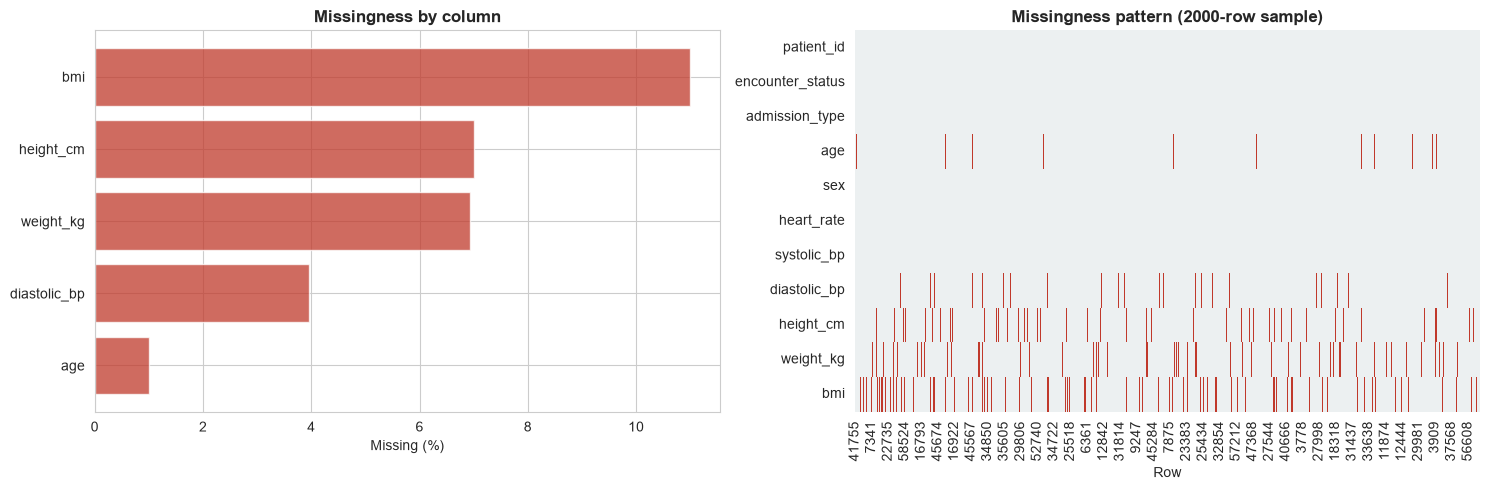


Height and weight go missing together, which is what you would expect:
if nobody measured the patient, both are absent, and BMI cannot be derived.


In [7]:
# Missing data analysis
missing = pd.DataFrame({
    'missing': df.isna().sum(),
    'pct': (df.isna().mean() * 100).round(2),
}).sort_values('missing', ascending=False)

print("Missing values by column:")
display(missing[missing['missing'] > 0])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cols = missing[missing['missing'] > 0]
axes[0].barh(cols.index, cols['pct'], color='#c0392b', alpha=0.75)
axes[0].set_xlabel('Missing (%)')
axes[0].set_title('Missingness by column', fontweight='bold')
axes[0].invert_yaxis()

# A missingness heatmap shows whether nulls co-occur, which changes how you impute.
sample = df.sample(min(2000, len(df)), random_state=0)
sns.heatmap(sample.isna().T, cbar=False, ax=axes[1],
            cmap=['#ecf0f1', '#c0392b'], yticklabels=True)
axes[1].set_title('Missingness pattern (2000-row sample)', fontweight='bold')
axes[1].set_xlabel('Row')

plt.tight_layout()
plt.show()

print("\nHeight and weight go missing together, which is what you would expect:")
print("if nobody measured the patient, both are absent, and BMI cannot be derived.")


In [8]:
# Duplicate rows: usually a bad join in the extract, not a real repeated measurement
dupes = df.duplicated().sum()
print(f"Exact duplicate rows: {dupes:,}  ({dupes / len(df):.2%})")

if dupes:
    print("\nExample of a duplicated row:")
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(4))
    print("Left in place for now. Deduplicate before modelling, or these rows are")
    print("counted twice and leak between the train and test splits.")


Exact duplicate rows: 1,328  (1.96%)

Example of a duplicated row:


,patient_id,encounter_status,admission_type,age,sex,heart_rate,systolic_bp,diastolic_bp,height_cm,weight_kg,bmi
2984,100044,Unknown,Maternity,70.0,F,87.8,131.2,85.8,163.1,83.2,31.3
17143,100044,Unknown,Maternity,70.0,F,87.8,131.2,85.8,163.1,83.2,31.3
1099,100049,Discharged,Emergency,74.0,M,82.8,144.1,86.4,NaN,87.9,27.5
62733,100049,Discharged,Emergency,74.0,M,82.8,144.1,86.4,NaN,87.9,27.5


Left in place for now. Deduplicate before modelling, or these rows are
counted twice and leak between the train and test splits.


## 4. Categorical Features

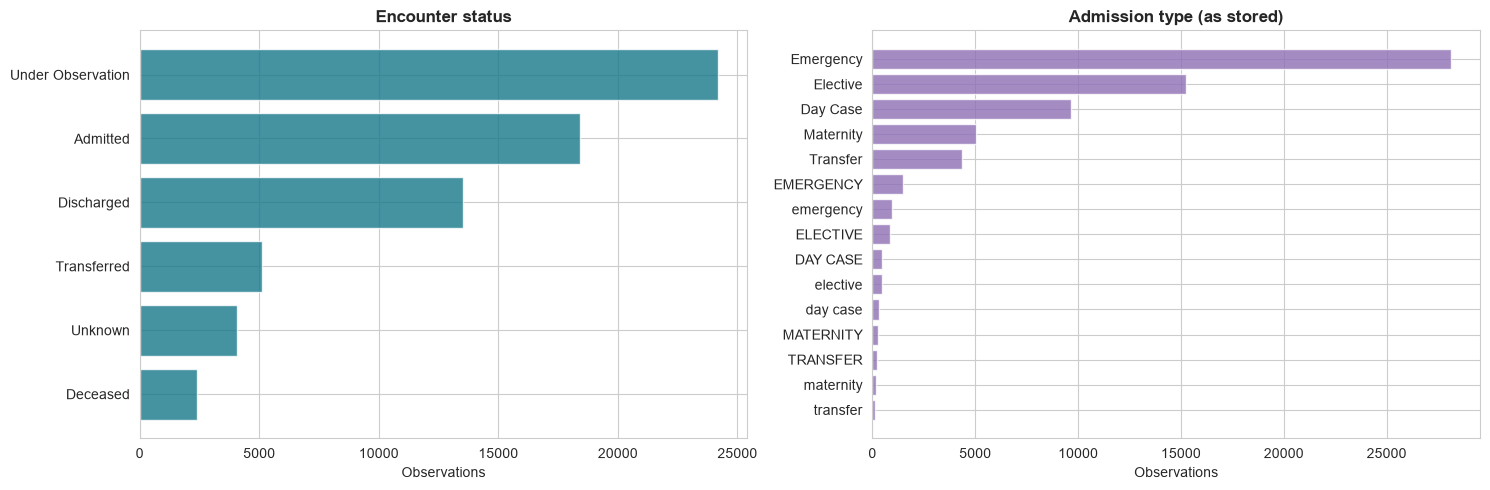

Encounter status values:
encounter_status
Under Observation    24206
Admitted             18399
Discharged           13516
Transferred           5128
Unknown               4066
Deceased              2411


In [9]:
# Encounter status
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

status_counts = df['encounter_status'].value_counts()
axes[0].barh(status_counts.index, status_counts.values, color='#16788a', alpha=0.8)
axes[0].set_xlabel('Observations')
axes[0].set_title('Encounter status', fontweight='bold')
axes[0].invert_yaxis()

admit_counts = df['admission_type'].value_counts()
axes[1].barh(admit_counts.index, admit_counts.values, color='#8e6fb5', alpha=0.8)
axes[1].set_xlabel('Observations')
axes[1].set_title('Admission type (as stored)', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("Encounter status values:")
print(status_counts.to_string())


In [10]:
# Two classic categorical traps live in these columns.

# Trap 1: a sentinel string standing in for a null.
unknown = (df['encounter_status'] == 'Unknown').sum()
print(f"Trap 1 - sentinel value: 'Unknown' appears {unknown:,} times "
      f"({unknown / len(df):.1%})")
print("        df.isna() does NOT count these. They are missing data wearing a costume.")

# Trap 2: the same category stored with different casing by different feeder systems.
print(f"\nTrap 2 - inconsistent casing: {df['admission_type'].nunique()} distinct "
      f"admission_type values for what should be 5 categories")
print(f"        {sorted(df['admission_type'].dropna().unique())}")

print("\nAfter normalizing case:")
normalized = df['admission_type'].str.title()
print(normalized.value_counts().to_string())
print(f"\n{normalized.nunique()} real categories. A model trained on the raw column")
print("would treat EMERGENCY and Emergency as unrelated.")


Trap 1 - sentinel value: 'Unknown' appears 4,066 times (6.0%)
        df.isna() does NOT count these. They are missing data wearing a costume.

Trap 2 - inconsistent casing: 15 distinct admission_type values for what should be 5 categories
        ['DAY CASE', 'Day Case', 'ELECTIVE', 'EMERGENCY', 'Elective', 'Emergency', 'MATERNITY', 'Maternity', 'TRANSFER', 'Transfer', 'day case', 'elective', 'emergency', 'maternity', 'transfer']

After normalizing case:
admission_type
Emergency    30534
Elective     16560
Day Case     10450
Maternity     5486
Transfer      4696

5 real categories. A model trained on the raw column
would treat EMERGENCY and Emergency as unrelated.


## 5. Numerical Features

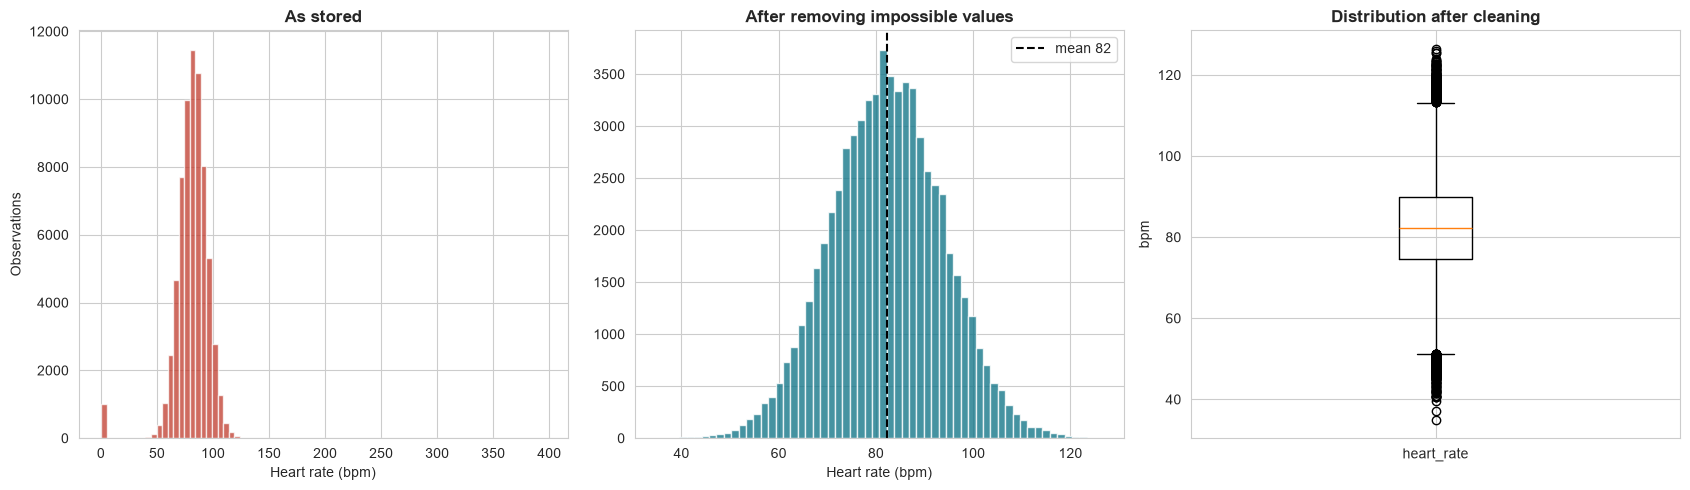

Removed 1,051 rows (1.6%) as physiologically impossible.
Mean heart rate: 81.2 as stored, 82.3 after cleaning.

That gap is the cost of not looking. The zeros drag the mean down by several bpm.


In [11]:
# Heart rate, with and without the impossible values
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(df['heart_rate'].dropna(), bins=80, color='#c0392b', alpha=0.75)
axes[0].set_xlabel('Heart rate (bpm)')
axes[0].set_ylabel('Observations')
axes[0].set_title('As stored', fontweight='bold')

valid_hr = df.loc[df['heart_rate'].between(30, 220, inclusive='both'), 'heart_rate']
axes[1].hist(valid_hr, bins=60, color='#16788a', alpha=0.8)
axes[1].set_xlabel('Heart rate (bpm)')
axes[1].set_title('After removing impossible values', fontweight='bold')
axes[1].axvline(valid_hr.mean(), color='k', linestyle='--',
                label=f'mean {valid_hr.mean():.0f}')
axes[1].legend()

axes[2].boxplot([valid_hr], tick_labels=['heart_rate'])
axes[2].set_ylabel('bpm')
axes[2].set_title('Distribution after cleaning', fontweight='bold')

plt.tight_layout()
plt.show()

removed = len(df) - len(valid_hr)
print(f"Removed {removed:,} rows ({removed / len(df):.1%}) as physiologically impossible.")
print(f"Mean heart rate: {df['heart_rate'].mean():.1f} as stored, "
      f"{valid_hr.mean():.1f} after cleaning.")
print("\nThat gap is the cost of not looking. The zeros drag the mean down by several bpm.")


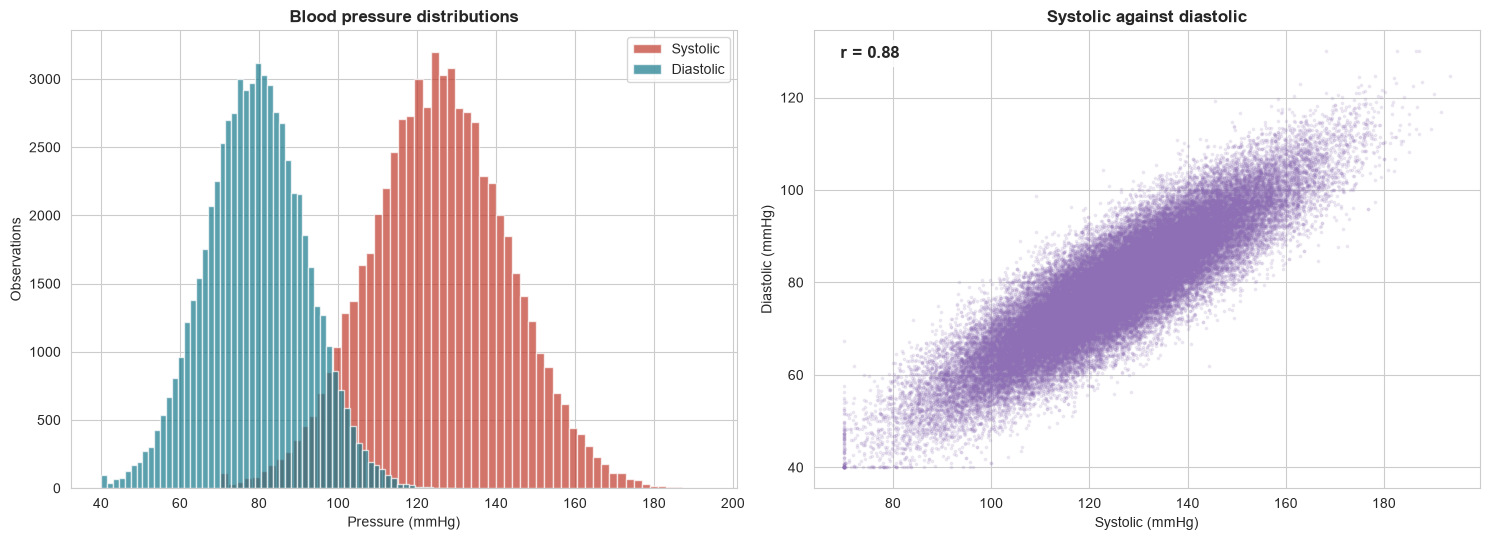

Systolic and diastolic correlate at r = 0.88.
Strongly related columns matter for two reasons: a linear model will suffer from
the collinearity, and either column can often stand in when the other is missing.


In [12]:
# Blood pressure: two related measurements
bp = df[(df['systolic_bp'] > 0) & (df['diastolic_bp'] > 0)].dropna(
    subset=['systolic_bp', 'diastolic_bp'])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].hist(bp['systolic_bp'], bins=60, alpha=0.7, label='Systolic', color='#c0392b')
axes[0].hist(bp['diastolic_bp'], bins=60, alpha=0.7, label='Diastolic', color='#16788a')
axes[0].set_xlabel('Pressure (mmHg)')
axes[0].set_ylabel('Observations')
axes[0].set_title('Blood pressure distributions', fontweight='bold')
axes[0].legend()

axes[1].scatter(bp['systolic_bp'], bp['diastolic_bp'], s=3, alpha=0.12, color='#8e6fb5')
axes[1].set_xlabel('Systolic (mmHg)')
axes[1].set_ylabel('Diastolic (mmHg)')
axes[1].set_title('Systolic against diastolic', fontweight='bold')
r = bp['systolic_bp'].corr(bp['diastolic_bp'])
axes[1].text(0.04, 0.94, f'r = {r:.2f}', transform=axes[1].transAxes,
             fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.85))

plt.tight_layout()
plt.show()

print(f"Systolic and diastolic correlate at r = {r:.2f}.")
print("Strongly related columns matter for two reasons: a linear model will suffer from")
print("the collinearity, and either column can often stand in when the other is missing.")


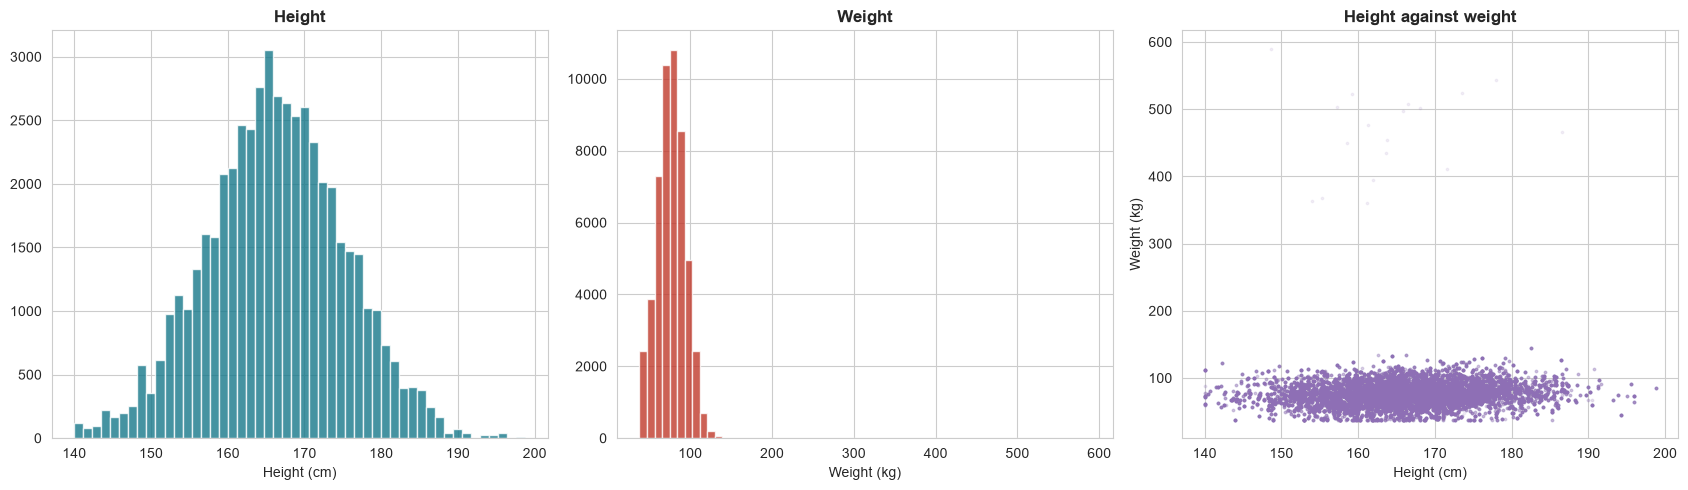

BMI recomputed from height and weight disagrees with the stored BMI by more
than 0.5 in 18 of 51,689 rows (0.03%).

A derived column you can recompute is a free consistency check. Use it.
Weight outliers above 300 kg: 25 rows.


In [13]:
# Anthropometrics, and a derived column that can be checked against its parents
meas = df.dropna(subset=['height_cm', 'weight_kg', 'bmi'])
meas = meas[(meas['weight_kg'] > 0) & (meas['height_cm'] > 0)]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].hist(meas['height_cm'], bins=50, color='#16788a', alpha=0.8)
axes[0].set_xlabel('Height (cm)'); axes[0].set_title('Height', fontweight='bold')

axes[1].hist(meas['weight_kg'], bins=60, color='#c0392b', alpha=0.8)
axes[1].set_xlabel('Weight (kg)'); axes[1].set_title('Weight', fontweight='bold')

axes[2].scatter(meas['height_cm'], meas['weight_kg'], s=3, alpha=0.1, color='#8e6fb5')
axes[2].set_xlabel('Height (cm)'); axes[2].set_ylabel('Weight (kg)')
axes[2].set_title('Height against weight', fontweight='bold')

plt.tight_layout()
plt.show()

# BMI is derived, so it can be recomputed and compared. Always do this.
recomputed = meas['weight_kg'] / (meas['height_cm'] / 100) ** 2
disagreement = (recomputed - meas['bmi']).abs()
print(f"BMI recomputed from height and weight disagrees with the stored BMI by more")
print(f"than 0.5 in {(disagreement > 0.5).sum():,} of {len(meas):,} rows "
      f"({(disagreement > 0.5).mean():.2%}).")
print("\nA derived column you can recompute is a free consistency check. Use it.")
print(f"Weight outliers above 300 kg: {(df['weight_kg'] > 300).sum()} rows.")


## 6. Cross-Feature Analysis

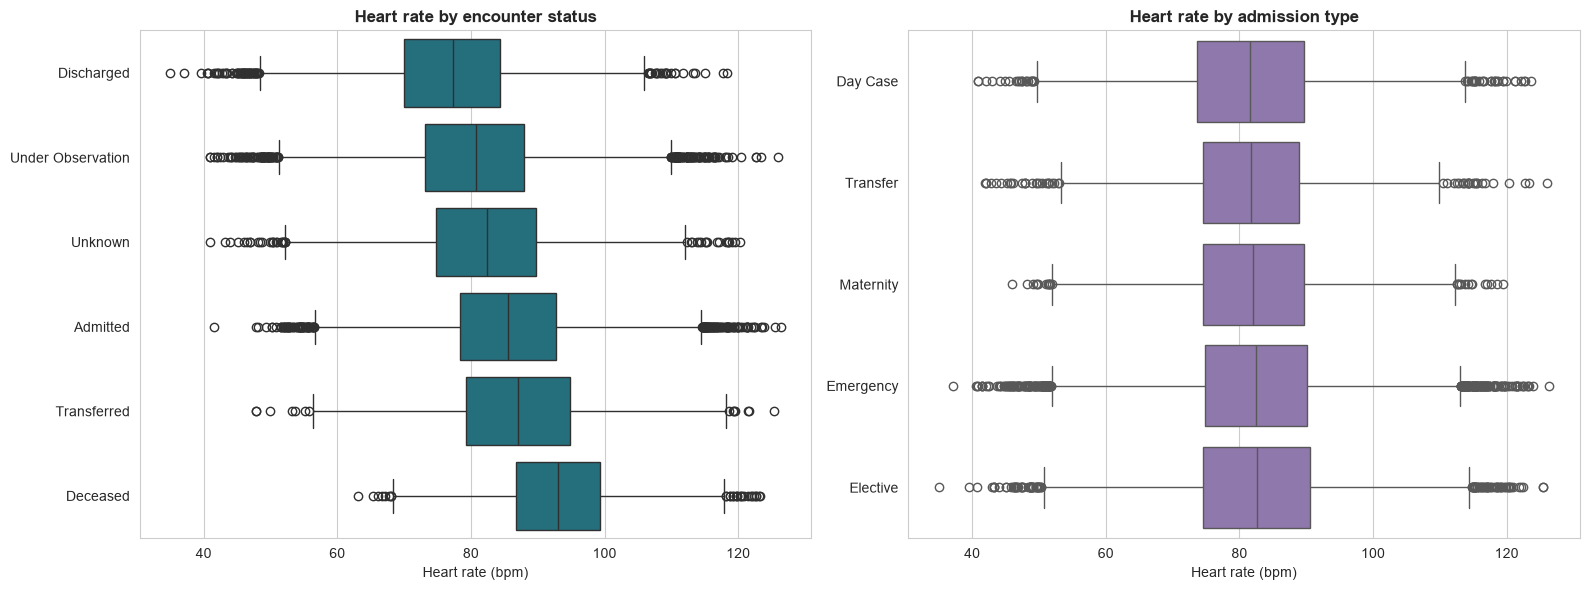

                   count  mean   std
encounter_status                    
Admitted           18124  85.5  10.8
Deceased            2369  93.3   9.7
Discharged         13288  77.1  10.6
Transferred         5070  87.0  11.0
Under Observation  23820  80.6  11.0
Unknown             4004  82.2  11.4

Sicker statuses run higher heart rates, which is the direction you would expect.
A relationship that runs the wrong way is a sign the data is mislabelled.


In [14]:
# Heart rate by encounter status and admission type
clean = df[df['heart_rate'].between(30, 220)].copy()
clean['admission_type'] = clean['admission_type'].str.title()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

order = clean.groupby('encounter_status')['heart_rate'].median().sort_values().index
sns.boxplot(data=clean, y='encounter_status', x='heart_rate', order=order,
            ax=axes[0], color='#16788a')
axes[0].set_title('Heart rate by encounter status', fontweight='bold')
axes[0].set_xlabel('Heart rate (bpm)'); axes[0].set_ylabel('')

order2 = clean.groupby('admission_type')['heart_rate'].median().sort_values().index
sns.boxplot(data=clean, y='admission_type', x='heart_rate', order=order2,
            ax=axes[1], color='#8e6fb5')
axes[1].set_title('Heart rate by admission type', fontweight='bold')
axes[1].set_xlabel('Heart rate (bpm)'); axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

print(clean.groupby('encounter_status')['heart_rate'].agg(['count', 'mean', 'std']).round(1).to_string())
print("\nSicker statuses run higher heart rates, which is the direction you would expect.")
print("A relationship that runs the wrong way is a sign the data is mislabelled.")


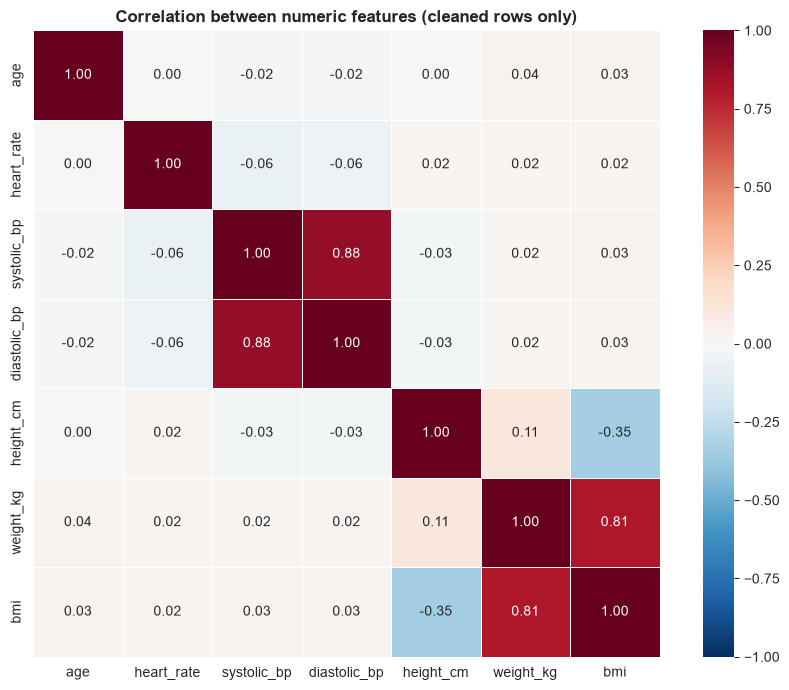

Computed on 47,815 rows that survive every validity filter.

The strongest pairs are the ones you would predict: systolic with diastolic,
and BMI with weight. BMI is derived from weight, so that correlation carries no
new information. Feeding both to a linear model is asking for trouble.


In [15]:
# Correlation matrix
num_cols = ['age', 'heart_rate', 'systolic_bp', 'diastolic_bp',
            'height_cm', 'weight_kg', 'bmi']
valid = df[
    df['heart_rate'].between(30, 220)
    & df['systolic_bp'].between(50, 220)
    & df['age'].between(0, 120)
    & (df['weight_kg'] > 0)
][num_cols].dropna()

corr = valid.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Correlation between numeric features (cleaned rows only)',
             fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Computed on {len(valid):,} rows that survive every validity filter.")
print("\nThe strongest pairs are the ones you would predict: systolic with diastolic,")
print("and BMI with weight. BMI is derived from weight, so that correlation carries no")
print("new information. Feeding both to a linear model is asking for trouble.")


## 7. Per-Patient Observation Timelines

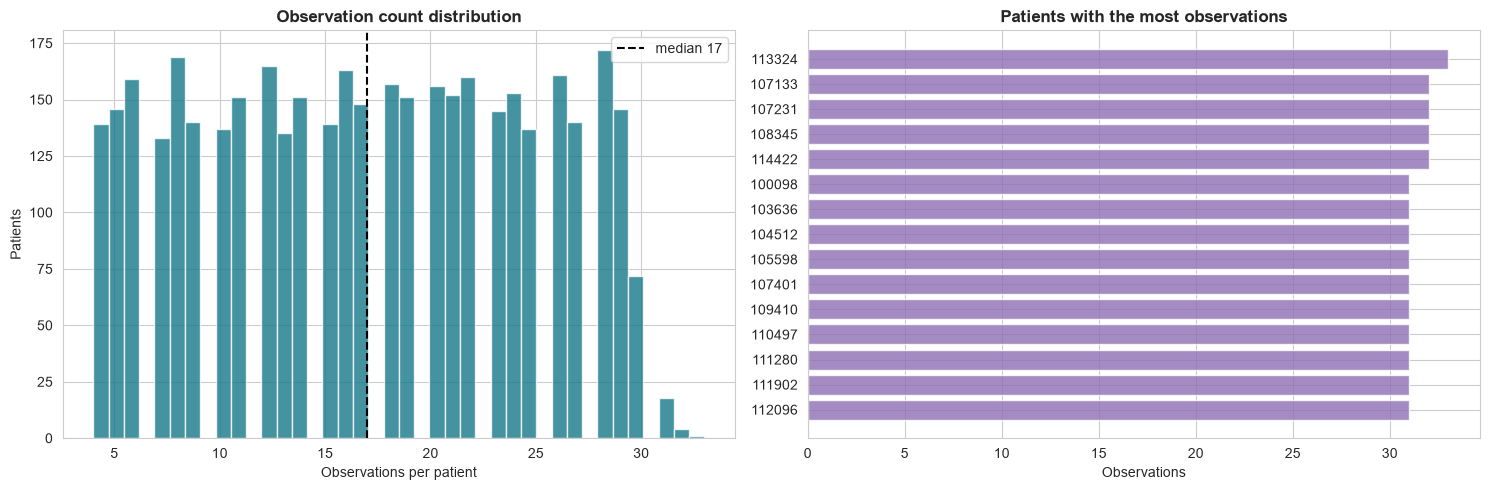

Observations per patient: min 4, median 17, max 33

This distribution matters more than it looks. Patients contributing many rows
dominate any model trained row-by-row, and splitting rows at random between train
and test leaks the same patient into both. Split by patient, not by row.


In [16]:
# How many observations does each patient contribute?
per_patient = df.groupby('patient_id').size()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(per_patient, bins=40, color='#16788a', alpha=0.8)
axes[0].set_xlabel('Observations per patient')
axes[0].set_ylabel('Patients')
axes[0].set_title('Observation count distribution', fontweight='bold')
axes[0].axvline(per_patient.median(), color='k', linestyle='--',
                label=f'median {per_patient.median():.0f}')
axes[0].legend()

top = per_patient.nlargest(15)
axes[1].barh([str(i) for i in top.index], top.values, color='#8e6fb5', alpha=0.8)
axes[1].set_xlabel('Observations')
axes[1].set_title('Patients with the most observations', fontweight='bold')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print(f"Observations per patient: min {per_patient.min()}, "
      f"median {per_patient.median():.0f}, max {per_patient.max()}")
print("\nThis distribution matters more than it looks. Patients contributing many rows")
print("dominate any model trained row-by-row, and splitting rows at random between train")
print("and test leaks the same patient into both. Split by patient, not by row.")


Patient 113324: 33 observations, admission type Day Case, status Transferred


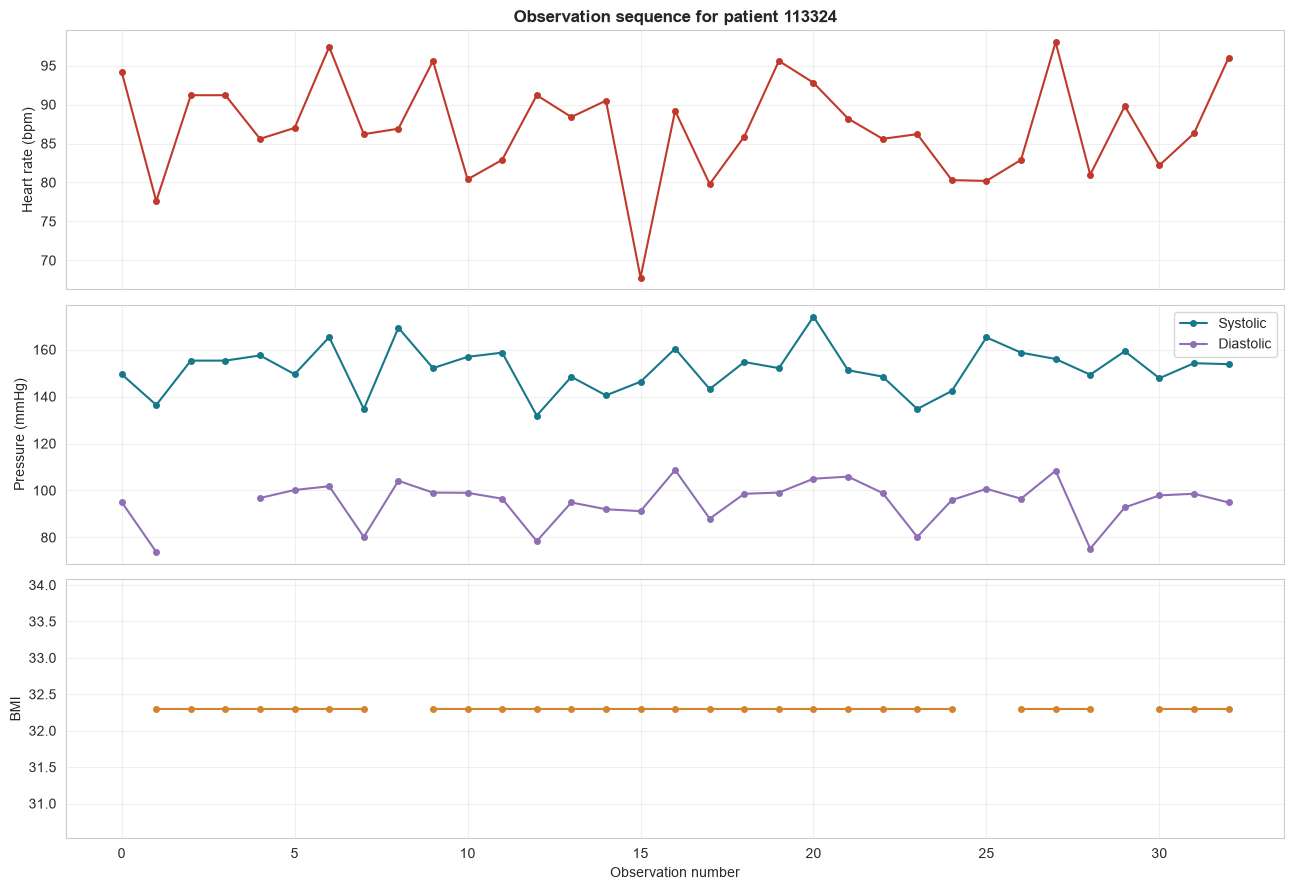


BMI is flat because it is a patient-level attribute repeated on every row,
not something measured each time. Repeating a constant down a column does not
make it a time series, and a model cannot learn anything from it over time.


In [17]:
# Look at one well-observed patient in detail
target = per_patient.idxmax()
patient = df[df['patient_id'] == target].reset_index(drop=True)

print(f"Patient {target}: {len(patient)} observations, "
      f"admission type {patient['admission_type'].iloc[0]}, "
      f"status {patient['encounter_status'].iloc[0]}")

fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
seq = range(len(patient))

axes[0].plot(seq, patient['heart_rate'], 'o-', color='#c0392b', markersize=4)
axes[0].set_ylabel('Heart rate (bpm)')
axes[0].set_title(f'Observation sequence for patient {target}', fontweight='bold')

axes[1].plot(seq, patient['systolic_bp'], 'o-', color='#16788a',
             markersize=4, label='Systolic')
axes[1].plot(seq, patient['diastolic_bp'], 'o-', color='#8e6fb5',
             markersize=4, label='Diastolic')
axes[1].set_ylabel('Pressure (mmHg)')
axes[1].legend()

axes[2].plot(seq, patient['bmi'], 'o-', color='#d4842a', markersize=4)
axes[2].set_ylabel('BMI')
axes[2].set_xlabel('Observation number')

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("\nBMI is flat because it is a patient-level attribute repeated on every row,")
print("not something measured each time. Repeating a constant down a column does not")
print("make it a time series, and a model cannot learn anything from it over time.")


## 8. Data Quality Summary and Recommendations

In [18]:
print("=" * 66)
print("DATA QUALITY SUMMARY")
print("=" * 66)

n = len(df)
print(f"\nExtract: {n:,} rows, {df['patient_id'].nunique():,} patients, "
      f"{len(df.columns)} columns\n")

issues = []
issues.append(("Exact duplicate rows", df.duplicated().sum()))
issues.append(("Missing BMI", df['bmi'].isna().sum()))
issues.append(("Missing weight", df['weight_kg'].isna().sum()))
issues.append(("Missing height", df['height_cm'].isna().sum()))
issues.append(("Status recorded as 'Unknown'", (df['encounter_status'] == 'Unknown').sum()))
issues.append(("Heart rate of exactly 0", (df['heart_rate'] == 0).sum()))
issues.append(("Heart rate above 250", (df['heart_rate'] > 250).sum()))
issues.append(("Blood pressure of exactly 0", (df['systolic_bp'] == 0).sum()))
issues.append(("Weight of exactly 0", (df['weight_kg'] == 0).sum()))
issues.append(("Age above 120", (df['age'] > 120).sum()))
issues.append(("Admission type casing variants",
               df['admission_type'].nunique() - df['admission_type'].str.title().nunique()))

print(f"{'Issue':38} {'Rows':>8} {'Share':>8}")
print("-" * 66)
for label, count in issues:
    print(f"{label:38} {count:8,} {count / n:8.2%}")

usable = df[
    ~df.duplicated()
    & df['heart_rate'].between(30, 220)
    & df['systolic_bp'].between(50, 220)
    & df['age'].between(0, 120)
    & (df['encounter_status'] != 'Unknown')
]
print("-" * 66)
print(f"{'Rows surviving every filter':38} {len(usable):8,} {len(usable) / n:8.2%}")

print("\n" + "=" * 66)
print("RECOMMENDATIONS")
print("=" * 66)
print("""
1. Deduplicate first. Do it before splitting, or the same row lands in train and test.

2. Treat sentinels as missing. 'Unknown' is a null. Convert it, then decide what to do,
   rather than letting a model learn a category that means "we do not know".

3. Replace impossible values with nulls, do not delete the row. A heart rate of 0 is a
   failed measurement; the rest of that row is probably fine.

4. Normalize categorical casing at load time. One line, and it collapses eleven spurious
   categories back into five real ones.

5. Recompute derived columns. BMI can be checked against height and weight. Where they
   disagree, trust the parents.

6. Split by patient, never by row. Rows from the same patient are not independent, and a
   row-level split inflates every performance number you report.

7. Record what you did. A cleaning decision that is not written down is one nobody can
   question later, including you.
""")


DATA QUALITY SUMMARY

Extract: 67,726 rows, 4,000 patients, 11 columns

Issue                                      Rows    Share
------------------------------------------------------------------
Exact duplicate rows                      1,328    1.96%
Missing BMI                               7,447   11.00%
Missing weight                            4,699    6.94%
Missing height                            4,744    7.00%
Status recorded as 'Unknown'              4,066    6.00%
Heart rate of exactly 0                   1,009    1.49%
Heart rate above 250                         42    0.06%
Blood pressure of exactly 0                 808    1.19%
Weight of exactly 0                         542    0.80%
Age above 120                                30    0.04%
Admission type casing variants               10    0.01%
------------------------------------------------------------------
Rows surviving every filter              60,084   88.72%

RECOMMENDATIONS

1. Deduplicate first. Do it before 

## 9. Next Steps

With the extract understood, the rest of the course applies:

- **[Decision Trees to Boosting](s2_02_decision_trees_to_boosting.ipynb)** — build a first classifier on tabular clinical data
- **[Precision and Recall](s2_18_precision_recall_clinical.ipynb)** — why accuracy misleads when outcomes are rare
- **[SHAP Values](s2_19_shap_values.ipynb)** — explain what a model learned from data like this
- **[Bias and Variance](s2_17_bias_variance_tradeoff.ipynb)** — how much of the pattern is real

### The point of this notebook

The defects above were injected on purpose, but not invented. Sentinel values, casing
drift between feeder systems, monitors writing zeros, and derived columns disagreeing
with their parents are what a real hospital extract looks like on arrival.

A model trained on the uncleaned version of this file would have run without error and
produced confident, wrong answers. That is the failure mode worth remembering: bad data
does not announce itself, it just quietly degrades everything downstream.


In [19]:
# Export key statistics for later reference
summary = {
    'rows': int(len(df)),
    'patients': int(df['patient_id'].nunique()),
    'duplicate_rows': int(df.duplicated().sum()),
    'usable_rows': int(len(usable)),
    'usable_share': round(len(usable) / len(df), 4),
    'mean_heart_rate_cleaned': round(float(df.loc[df['heart_rate'].between(30, 220), 'heart_rate'].mean()), 1),
    'missing_bmi_pct': round(float(df['bmi'].isna().mean() * 100), 2),
}

stats_df = pd.DataFrame([summary]).T.rename(columns={0: 'value'})
display(stats_df)

stats_df.to_csv('encounters_quality_summary.csv')
print("\nWrote encounters_quality_summary.csv")


,value
rows,67726.0000
patients,4000.0000
duplicate_rows,1328.0000
usable_rows,60084.0000
usable_share,0.8872
mean_heart_rate_cleaned,82.3000
missing_bmi_pct,11.0000



Wrote encounters_quality_summary.csv
